<a href="https://colab.research.google.com/github/alokchoudharyguliya/ML/blob/main/KerasANN_Disease_Predict/%5BLearning%5DKerasANN_Disease_Predict.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Custom Dataset

In [ ]:
import numpy as np
from random import randint
from sklearn.utils import shuffle
from sklearn.preprocessing import MinMaxScaler

In [ ]:
train_labels=[]
train_samples=[]

Generating the data


In [ ]:
for i in range(50):
  random_younger=randint(13,64)
  train_samples.append(random_younger)
  train_labels.append(1)

  random_older=randint(65,100)
  train_samples.append(random_older)
  train_labels.append(0)

for i in range(1000):
  random_younger=randint(13,64)
  train_samples.append(random_younger)
  train_labels.append(0)

  random_older=randint(65,100)
  train_samples.append(random_older)
  train_labels.append(1)

In [ ]:
for i in train_samples:
  print(i)

42
90
29
66
44
93
30
68
41
67
19
94
32
98
24
98
60
76
22
65
46
97
61
99
20
78
23
69
41
80
31
95
53
75
45
81
54
79
61
76
17
95
41
85
31
72
26
66
59
81
58
96
55
65
35
67
35
90
23
77
37
80
54
87
28
88
49
69
18
90
35
87
31
82
20
86
40
72
35
76
43
67
30
75
44
75
58
85
60
65
33
67
15
98
16
75
28
69
29
94
34
77
62
72
55
72
27
87
25
94
48
87
63
76
27
85
36
84
48
91
19
74
21
92
42
81
33
71
64
77
15
83
22
81
46
86
64
93
59
100
36
67
53
81
36
73
13
90
42
81
32
92
47
90
52
76
33
91
24
97
16
93
31
85
29
67
60
79
26
84
14
82
18
90
63
97
63
95
57
92
29
72
53
65
39
78
53
80
37
99
30
73
58
91
56
66
30
90
13
85
58
98
41
82
15
86
30
65
56
97
63
76
60
85
32
85
19
82
16
93
54
91
43
65
45
97
56
100
48
89
53
100
58
67
24
78
51
99
33
80
27
74
24
85
50
80
34
76
14
73
25
81
26
76
53
67
43
72
35
99
50
99
32
81
50
76
22
65
19
85
42
92
56
79
63
96
62
89
64
83
58
76
44
91
20
80
63
96
18
93
45
89
56
92
28
68
27
95
32
66
60
95
51
96
34
97
60
96
20
79
55
79
30
86
41
90
55
91
15
74
54
80
64
70
39
73
50
74
37
67
30
98
2

In [ ]:
import pandas as pd
# pd.DataFrame(train_samples,train_labels,columns=["Age"])
pd.DataFrame({"Target":train_samples,"Age":train_labels})

,Target,Age
0,42,1
1,90,0
2,29,1
3,66,0
4,44,1
...,...,...
2095,70,1
2096,18,0
2097,76,1
2098,40,0


In [ ]:
train_labels=np.array(train_labels)
train_samples=np.array(train_samples)
train_labels,train_samples=shuffle(train_labels,train_samples)

Scaling or Preprocessing the DATA

In [ ]:
sc=MinMaxScaler(feature_range=(0,1))
scaled_train_samples=sc.fit_transform(train_samples.reshape(-1,1))

In [ ]:
for i in scaled_train_samples:
  print(i)

[0.06896552]
[0.96551724]
[0.81609195]
[0.85057471]
[0.8045977]
[0.8045977]
[0.50574713]
[0.1954023]
[0.93103448]
[0.96551724]
[0.71264368]
[0.09195402]
[0.37931034]
[0.73563218]
[0.35632184]
[0.96551724]
[0.33333333]
[0.32183908]
[0.47126437]
[0.54022989]
[0.04597701]
[0.51724138]
[0.74712644]
[0.67816092]
[0.22988506]
[0.57471264]
[0.49425287]
[0.27586207]
[0.72413793]
[0.97701149]
[0.7816092]
[0.8045977]
[0.6091954]
[0.67816092]
[0.03448276]
[0.77011494]
[0.63218391]
[0.01149425]
[1.]
[0.75862069]
[0.74712644]
[0.85057471]
[0.27586207]
[0.70114943]
[0.51724138]
[0.1954023]
[0.72413793]
[0.55172414]
[0.89655172]
[0.90804598]
[0.06896552]
[0.11494253]
[0.22988506]
[0.85057471]
[0.52873563]
[0.81609195]
[0.96551724]
[0.67816092]
[0.27586207]
[0.62068966]
[0.85057471]
[0.63218391]
[0.09195402]
[0.05747126]
[0.35632184]
[0.13793103]
[0.3908046]
[0.77011494]
[0.03448276]
[0.77011494]
[0.34482759]
[0.14942529]
[0.93103448]
[0.24137931]
[0.]
[0.68965517]
[0.57471264]
[0.03448276]
[0.0574712

Building the ANN

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.metrics import categorical_crossentropy

In [ ]:
physical_devices=tf.config.experimental.list_physical_devices('CPU')
print("NUM OF CPUs AVAILABLE :",len(physical_devices))
# tf.config.experimental.set_memory_growth(physical_devices[0],True)

NUM OF CPUs AVAILABLE : 1


In [ ]:
model=Sequential(
    [
        Dense(units=16,input_shape=(1,),activation="relu"),
        Dense(units=32,activation="relu"),
        Dense(units=2,activation="softmax")
    ]
)
# last dense layer is the output layer has two units or nodes as the output labels are two i.e. 0 and 1

In [ ]:
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 16)                32        
                                                                 
 dense_1 (Dense)             (None, 32)                544       
                                                                 
 dense_2 (Dense)             (None, 2)                 66        
                                                                 
Total params: 642 (2.51 KB)
Trainable params: 642 (2.51 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


Compiling the neural network

In [ ]:
model.compile(optimizer=Adam(learning_rate=0.0001),loss="sparse_categorical_crossentropy",metrics=['accuracy'])

Training the model with data

In [ ]:
model.fit(x=scaled_train_samples,y=train_labels,epochs=40,batch_size=10,shuffle=True,verbose=2,validation_split=0.1)

Epoch 1/40
189/189 - 1s - loss: 0.6760 - accuracy: 0.5148 - val_loss: 0.6589 - val_accuracy: 0.5857 - 1s/epoch - 7ms/step
Epoch 2/40
189/189 - 0s - loss: 0.6536 - accuracy: 0.6032 - val_loss: 0.6319 - val_accuracy: 0.6714 - 357ms/epoch - 2ms/step
Epoch 3/40
189/189 - 1s - loss: 0.6298 - accuracy: 0.6519 - val_loss: 0.6063 - val_accuracy: 0.7143 - 559ms/epoch - 3ms/step
Epoch 4/40
189/189 - 0s - loss: 0.6060 - accuracy: 0.6963 - val_loss: 0.5795 - val_accuracy: 0.7381 - 471ms/epoch - 2ms/step
Epoch 5/40
189/189 - 0s - loss: 0.5804 - accuracy: 0.7365 - val_loss: 0.5514 - val_accuracy: 0.7810 - 474ms/epoch - 3ms/step
Epoch 6/40
189/189 - 0s - loss: 0.5529 - accuracy: 0.7688 - val_loss: 0.5224 - val_accuracy: 0.8095 - 470ms/epoch - 2ms/step
Epoch 7/40
189/189 - 0s - loss: 0.5238 - accuracy: 0.8016 - val_loss: 0.4923 - val_accuracy: 0.8429 - 469ms/epoch - 2ms/step
Epoch 8/40
189/189 - 0s - loss: 0.4939 - accuracy: 0.8259 - val_loss: 0.4622 - val_accuracy: 0.8476 - 341ms/epoch - 2ms/step
Epo

In [ ]:
test_samples=[]
test_labels=[]

In [ ]:
for i in range(10):
  random_younger=randint(13,64)
  test_samples.append(random_younger)
  test_labels.append(0)

  random_older=randint(65,100)
  test_samples.append(random_younger)
  test_labels.append(1)

for i in range(200):
  random_younger=randint(13,64)
  test_samples.append(random_younger)
  test_labels.append(1)

  random_older=randint(65,100)
  test_samples.append(random_younger)
  test_labels.append(0)

In [ ]:
test_labels=np.array(test_labels)
test_samples=np.array(test_samples)
test_labels,test_samples=shuffle(test_labels,test_samples)

In [ ]:
scaled_test_samples=sc.fit_transform(test_samples.reshape(-1,1))

In [ ]:
predictions=model.predict(x=scaled_test_samples,batch_size=10,verbose=0)

In [ ]:
for i in predictions:
  print(i)

[0.9610856  0.03891424]
[0.9613257  0.03867432]
[0.03793874 0.96206117]
[0.9470739  0.05292606]
[0.06996701 0.9300329 ]
[0.890938   0.10906201]
[0.01361602 0.986384  ]
[0.11002978 0.88997024]
[0.02105889 0.9789411 ]
[0.9586299  0.04137013]
[0.06996701 0.9300329 ]
[0.96120584 0.0387941 ]
[0.9292999  0.07070005]
[0.01575193 0.98424816]
[0.01361602 0.986384  ]
[0.96120584 0.0387941 ]
[0.9613257  0.03867432]
[0.7276659  0.27233407]
[0.9521635  0.04783654]
[0.9606351  0.03936487]
[0.05939737 0.94060266]
[0.17775033 0.82224965]
[0.95932454 0.04067551]
[0.95499897 0.045001  ]
[0.96120584 0.0387941 ]
[0.95216346 0.04783654]
[0.0512118  0.94878817]
[0.9582507  0.04174915]
[0.9590056  0.04099439]
[0.9612059 0.0387941]
[0.11002978 0.88997024]
[0.9613257  0.03867432]
[0.86068267 0.1393173 ]
[0.02433353 0.97566646]
[0.77940446 0.22059552]
[0.890938   0.10906201]
[0.95932454 0.04067551]
[0.11002978 0.88997024]
[0.9608358 0.0391642]
[0.02810276 0.9718972 ]
[0.01575193 0.98424816]
[0.33325368 0.666746

In [ ]:
rounded_predictions=np.argmax(predictions,axis=-1)

In [ ]:
for i in rounded_predictions:
  print(i)

0
0
1
0
1
0
1
1
1
0
1
0
0
1
1
0
0
0
0
0
1
1
0
0
0
0
1
0
0
0
1
0
0
1
0
0
0
1
0
1
1
1
0
0
1
1
1
0
0
0
1
1
1
0
0
1
0
0
0
1
0
0
0
0
0
1
1
0
1
0
1
0
0
0
0
0
0
0
1
0
0
0
1
1
0
0
1
0
1
1
1
1
1
0
0
0
0
0
1
0
0
1
0
1
0
1
1
0
0
0
0
0
1
0
1
0
0
1
1
1
0
1
1
0
1
0
1
0
0
1
1
1
0
1
0
1
1
0
0
0
1
0
1
1
0
1
0
0
1
1
1
0
1
1
0
0
0
0
1
1
0
1
0
0
0
1
0
0
1
1
1
1
0
1
1
1
1
0
0
1
0
1
0
1
0
1
1
0
0
0
0
1
0
0
0
1
1
1
0
0
1
0
1
1
0
0
0
0
1
1
1
1
0
0
1
1
0
1
1
0
0
1
0
0
0
0
0
0
1
0
0
0
1
0
1
0
1
0
0
0
0
1
1
1
1
0
0
0
1
0
1
1
0
0
0
0
1
1
0
1
1
0
0
0
0
0
0
0
0
0
1
0
1
0
0
1
1
1
0
0
1
0
0
1
0
0
1
1
1
0
0
1
1
1
1
1
1
1
0
0
1
0
0
0
1
1
0
1
1
1
0
0
1
0
1
1
0
0
0
1
0
1
1
1
0
1
0
1
0
1
1
0
1
0
1
0
1
0
0
1
0
0
1
1
1
0
0
1
0
1
0
0
0
0
0
0
1
1
0
0
1
1
0
0
1
1
1
1
1
1
1
1
1
0
0
1
1
1
1
0
1
0
1
1
0
0
0
0
0
0
0
0
0
1
0
0
0
0
1
1
0
0
0
0
0
0
1
0
0
1
0
0
0
0
0
0
0
0
0
1


Confusion Matrix

In [ ]:
from sklearn.metrics import confusion_matrix
import itertools
import matplotlib.pyplot as plt

In [ ]:
cm=confusion_matrix(y_true=test_labels,y_pred=rounded_predictions)

In [ ]:
def plot_confusion_matrix(cm,classes,normalize=True,title='Confusion matrix',cmap=plt.cm.Blues):
  plt.imshow(cm,interpolation="nearest",cmap=cmap)
  plt.title(title)
  plt.colorbar()
  tick_marks=np.arange(len(classes))
  plt.xticks(tick_marks,classes,rotation=45)
  plt.yticks(tick_marks,classes)

  if normalize:
    cm=cm.astype('float')/cm.sum(axis=1)[:,np.newaxis]
    print("Normalized Confusion Matrix")
  else:
    print("Confusion matrix, without normalization")

  print(cm)

  thresh=cm.max()/2
  for i, j in itertools.product(range(cm.shape[0]),range(cm.shape[1])):
    plt.text(j,i,cm[i,j],horizontalalignment="center",color='white' if cm[i,j]>thresh else "black")
  plt.tight_layout()
  plt.ylabel("True Label")
  plt.xlabel("Predicted Label")

Normalized Confusion Matrix
[[0.56190476 0.43809524]
 [0.56190476 0.43809524]]


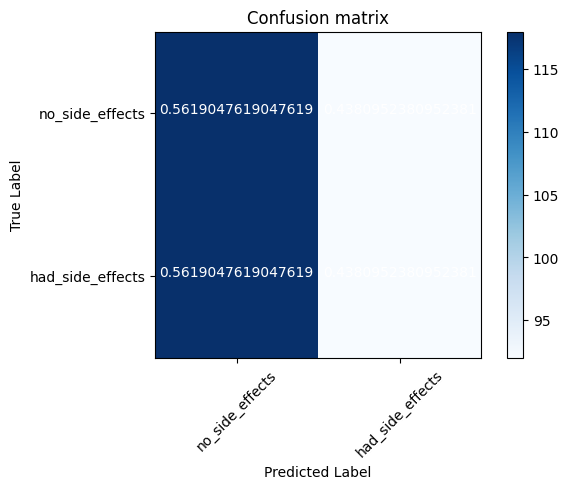

In [ ]:
cm_plot_labels=['no_side_effects','had_side_effects']
plot_confusion_matrix(cm=cm,classes=cm_plot_labels)

save and load a model

1. save model

In [ ]:
import os.path
if os.path.isfile('/content/models/medical_trial_model.h5') is False:
  model.save('/content/models/medical_trial_model.h5')

/usr/local/lib/python3.10/dist-packages/keras/src/engine/training.py:3103: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


In [ ]:
from tensorflow.keras.models import load_model
new_model=load_model('/content/models/medical_trial_model.h5')

In [ ]:
new_model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 16)                32        
                                                                 
 dense_1 (Dense)             (None, 32)                544       
                                                                 
 dense_2 (Dense)             (None, 2)                 66        
                                                                 
Total params: 642 (2.51 KB)
Trainable params: 642 (2.51 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [ ]:
new_model.get_weights()

[array([[ 0.57734424, -0.41101944,  0.53607106,  0.7411311 ,  0.36550218,
         -0.21314123,  0.69266784, -0.49036628,  0.51806647, -0.02022327,
         -0.09381515, -0.56692255, -0.24830493,  0.21842805,  0.26700252,
          0.4465312 ]], dtype=float32),
 array([ 0.13385111,  0.        , -0.15507843, -0.10967404, -0.14276344,
         0.        , -0.17073174,  0.        , -0.17681363,  0.2703778 ,
         0.        ,  0.        ,  0.        , -0.09270208, -0.11045567,
        -0.15092517], dtype=float32),
 array([[ 0.17963052, -0.22497919, -0.03840041,  0.22395563, -0.24583262,
         -0.16766775, -0.15717506, -0.04850867, -0.2025296 ,  0.17760083,
          0.2663614 ,  0.05364576,  0.3546844 ,  0.04784352,  0.10463951,
         -0.06005758, -0.12928453,  0.21709815, -0.09605539, -0.00286007,
          0.08779445,  0.43333644,  0.05918228, -0.23513734, -0.27815235,
         -0.27981442,  0.44714284,  0.05888148,  0.0363866 , -0.25906363,
          0.33325145, -0.17927282],
 

In [ ]:
new_model.optimizer

2. model.to_json

In [ ]:
json_string=model.to_json()

In [ ]:
json_string

'{"class_name": "Sequential", "config": {"name": "sequential", "layers": [{"module": "keras.layers", "class_name": "InputLayer", "config": {"batch_input_shape": [null, 1], "dtype": "float32", "sparse": false, "ragged": false, "name": "dense_input"}, "registered_name": null}, {"module": "keras.layers", "class_name": "Dense", "config": {"name": "dense", "trainable": true, "dtype": "float32", "batch_input_shape": [null, 1], "units": 16, "activation": "relu", "use_bias": true, "kernel_initializer": {"module": "keras.initializers", "class_name": "GlorotUniform", "config": {"seed": null}, "registered_name": null}, "bias_initializer": {"module": "keras.initializers", "class_name": "Zeros", "config": {}, "registered_name": null}, "kernel_regularizer": null, "bias_regularizer": null, "activity_regularizer": null, "kernel_constraint": null, "bias_constraint": null}, "registered_name": null, "build_config": {"input_shape": [null, 1]}}, {"module": "keras.layers", "class_name": "Dense", "config": {

In [ ]:
from tensorflow.keras.models import model_from_json
model_architecture=model_from_json(json_string)

#from tensorflow.keras.models import model_from_yaml
#model=model_from_yaml(yaml_string)

In [ ]:
model_architecture.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 16)                32        
                                                                 
 dense_1 (Dense)             (None, 32)                544       
                                                                 
 dense_2 (Dense)             (None, 2)                 66        
                                                                 
Total params: 642 (2.51 KB)
Trainable params: 642 (2.51 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


3. model.save_weights()

In [ ]:
import os.path
if os.path.isfile('/conetnt/models/my_model_weights.h5') is False:
  model.save_weights('/content/models/my_model_weights.h5')

In [ ]:
model2=Sequential(
    [
        Dense(units=16,input_shape=(1,),activation='relu'),
        Dense(units=32,activation="relu"),
        Dense(units=2,activation="softmax")
    ]
)

In [ ]:
model2.load_weights('/content/models/my_model_weights.h5')

In [ ]:
model2.get_weights()

[array([[ 0.57734424, -0.41101944,  0.53607106,  0.7411311 ,  0.36550218,
         -0.21314123,  0.69266784, -0.49036628,  0.51806647, -0.02022327,
         -0.09381515, -0.56692255, -0.24830493,  0.21842805,  0.26700252,
          0.4465312 ]], dtype=float32),
 array([ 0.13385111,  0.        , -0.15507843, -0.10967404, -0.14276344,
         0.        , -0.17073174,  0.        , -0.17681363,  0.2703778 ,
         0.        ,  0.        ,  0.        , -0.09270208, -0.11045567,
        -0.15092517], dtype=float32),
 array([[ 0.17963052, -0.22497919, -0.03840041,  0.22395563, -0.24583262,
         -0.16766775, -0.15717506, -0.04850867, -0.2025296 ,  0.17760083,
          0.2663614 ,  0.05364576,  0.3546844 ,  0.04784352,  0.10463951,
         -0.06005758, -0.12928453,  0.21709815, -0.09605539, -0.00286007,
          0.08779445,  0.43333644,  0.05918228, -0.23513734, -0.27815235,
         -0.27981442,  0.44714284,  0.05888148,  0.0363866 , -0.25906363,
          0.33325145, -0.17927282],
 